In [ ]:
# 1. Import necessary libraries
import pandas as pd
from sklearn.datasets import fetch_openml


In [ ]:
# # 2 Data Collection and Loading
# 2.1 Load the Boston Housing dataset
boston = fetch_openml(name='boston', version=1, as_frame=True)

#2.2 Convert into a Pandas DataFrame
df = boston.frame

# Display the first five rows
print(df.head())

      CRIM    ZN  INDUS CHAS    NOX     RM   AGE     DIS RAD    TAX  PTRATIO  \
0  0.00632  18.0   2.31    0  0.538  6.575  65.2  4.0900   1  296.0     15.3   
1  0.02731   0.0   7.07    0  0.469  6.421  78.9  4.9671   2  242.0     17.8   
2  0.02729   0.0   7.07    0  0.469  7.185  61.1  4.9671   2  242.0     17.8   
3  0.03237   0.0   2.18    0  0.458  6.998  45.8  6.0622   3  222.0     18.7   
4  0.06905   0.0   2.18    0  0.458  7.147  54.2  6.0622   3  222.0     18.7   

        B  LSTAT  MEDV  
0  396.90   4.98  24.0  
1  396.90   9.14  21.6  
2  392.83   4.03  34.7  
3  394.63   2.94  33.4  
4  396.90   5.33  36.2  


In [ ]:
# 3. Separate features and target variable
X = df.drop('MEDV', axis=1)
y = df['MEDV']

# 3.1 Display features
print("Features:")
print(X.columns.tolist())

#3.2 Display target variable
print("\nTarget variable:")
print(y.name)

#3.3 Display data types
print("\nData types:")
print(df.dtypes)

# 3.3 # Display dataset information
df.info()

# Display descriptive statistics
df.describe()

Features:
['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']

Target variable:
MEDV

Data types:
CRIM        float64
ZN          float64
INDUS       float64
CHAS       category
NOX         float64
RM          float64
AGE         float64
DIS         float64
RAD        category
TAX         float64
PTRATIO     float64
B           float64
LSTAT       float64
MEDV        float64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   CRIM     506 non-null    float64 
 1   ZN       506 non-null    float64 
 2   INDUS    506 non-null    float64 
 3   CHAS     506 non-null    category
 4   NOX      506 non-null    float64 
 5   RM       506 non-null    float64 
 6   AGE      506 non-null    float64 
 7   DIS      506 non-null    float64 
 8   RAD      506 non-null    category
 9   TAX      506 non-null  

,CRIM,ZN,INDUS,NOX,RM,AGE,DIS,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.554695,6.284634,68.574901,3.795043,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.115878,0.702617,28.148861,2.105710,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.385000,3.561000,2.900000,1.129600,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.449000,5.885500,45.025000,2.100175,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.538000,6.208500,77.500000,3.207450,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.624000,6.623500,94.075000,5.188425,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,0.871000,8.780000,100.000000,12.126500,711.000000,22.000000,396.900000,37.970000,50.000000


In [ ]:
# 4 EDA and Data Preprocessing

# 4.1  Check for missing/null values

print(df.isnull().sum())

print("Total missing values:", df.isnull().sum().sum())

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64
Total missing values: 0


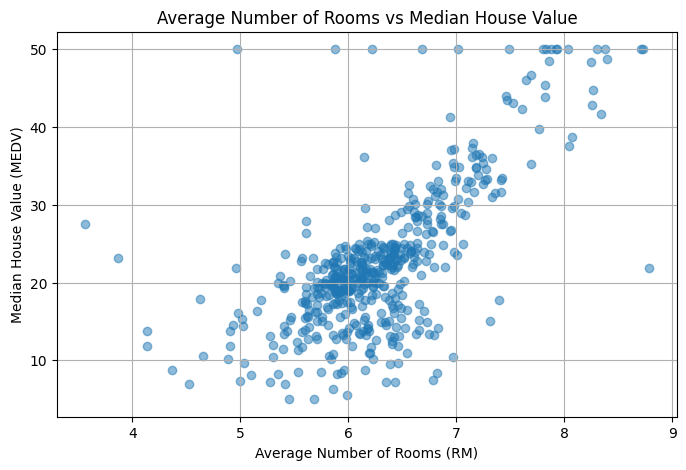

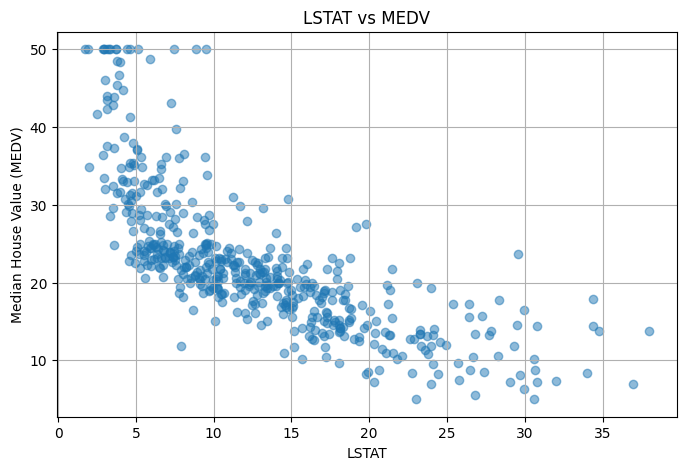

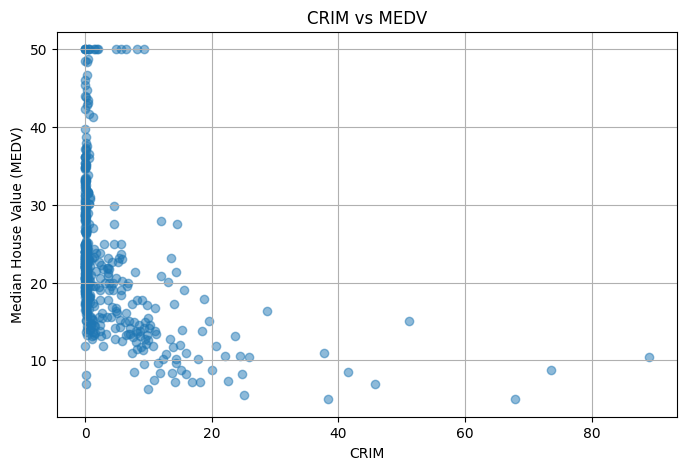

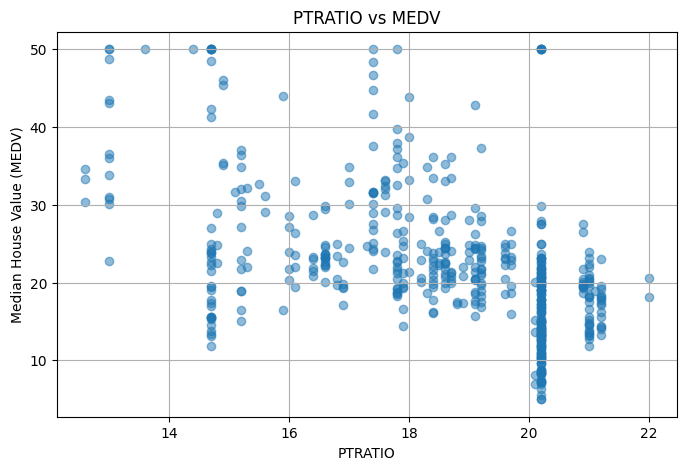

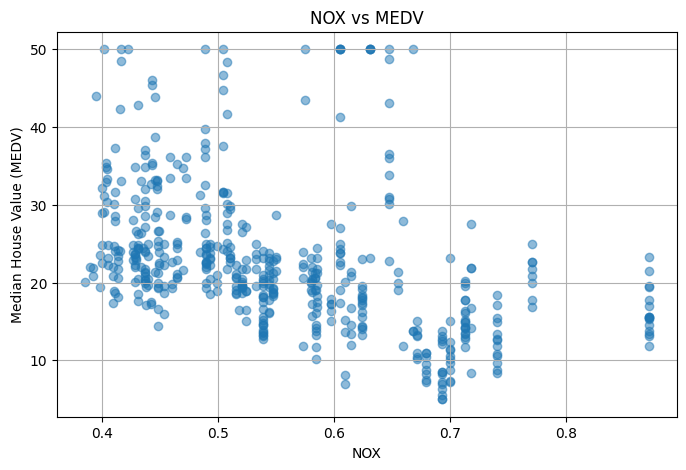

In [ ]:
# 5. Visualize the data
import matplotlib.pyplot as plt

# 5.1 Scatter plot: RM vs MEDV
plt.figure(figsize=(8, 5))
plt.scatter(df['RM'], df['MEDV'], alpha=0.5)

plt.title('Average Number of Rooms vs Median House Value')
plt.xlabel('Average Number of Rooms (RM)')
plt.ylabel('Median House Value (MEDV)')
plt.grid(True)
plt.show()

# 5.2 Scatter plots for other features
# Create scatter plots for selected features
features = ['LSTAT', 'CRIM', 'PTRATIO', 'NOX']

for feature in features:
    plt.figure(figsize=(8, 5))
    plt.scatter(df[feature], df['MEDV'], alpha=0.5)

    plt.title(f'{feature} vs MEDV')
    plt.xlabel(feature)
    plt.ylabel('Median House Value (MEDV)')
    plt.grid(True)
    plt.show()

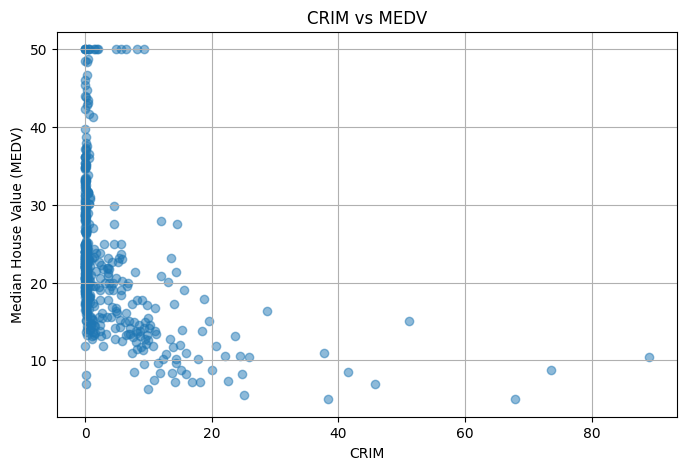

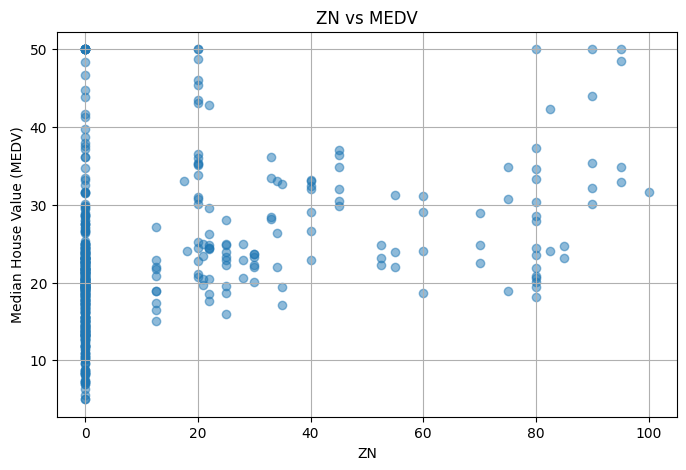

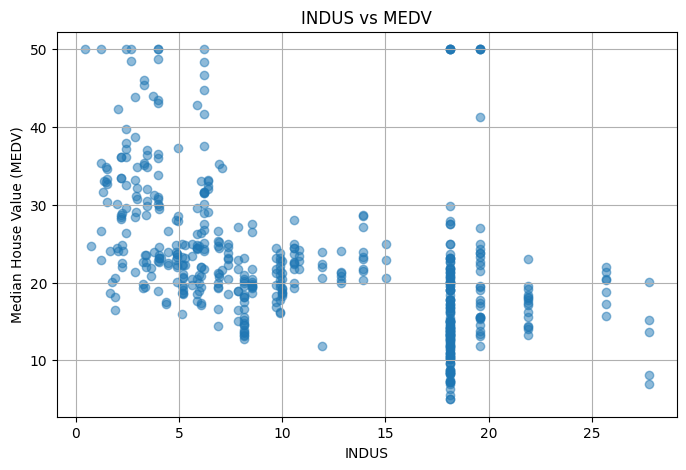

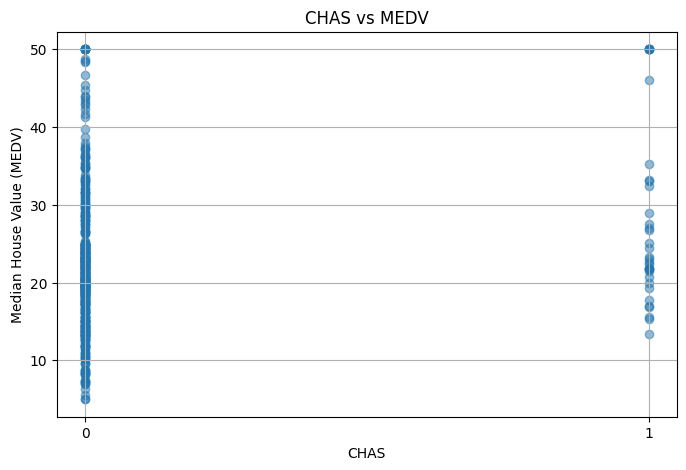

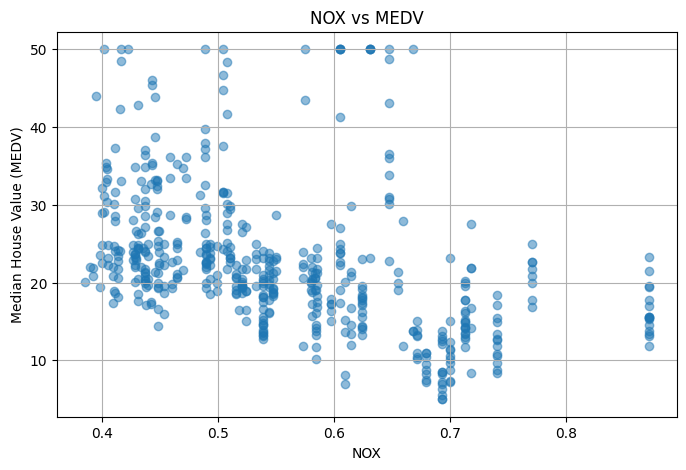

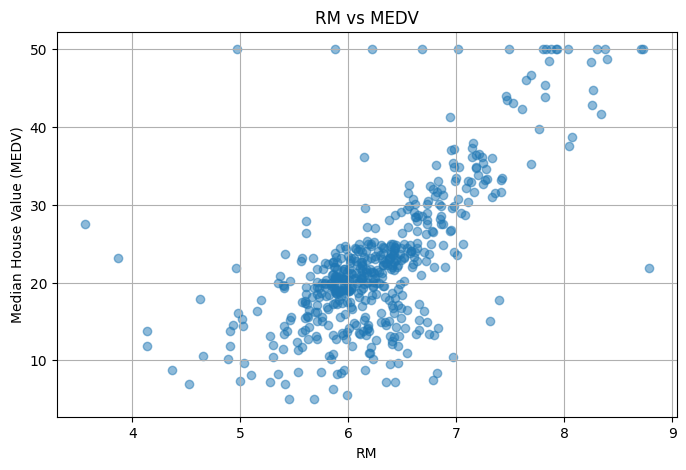

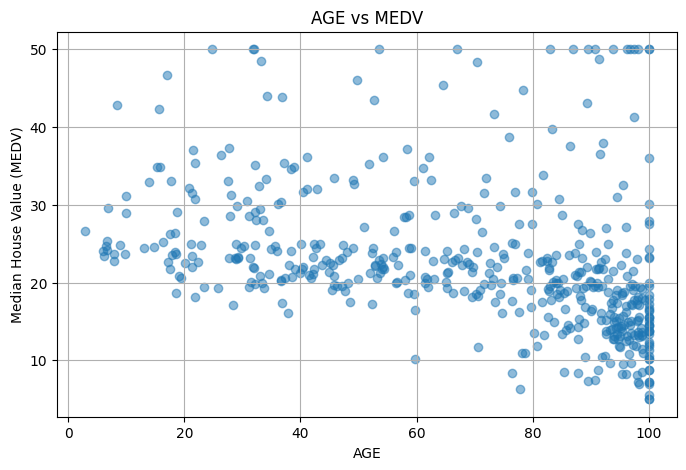

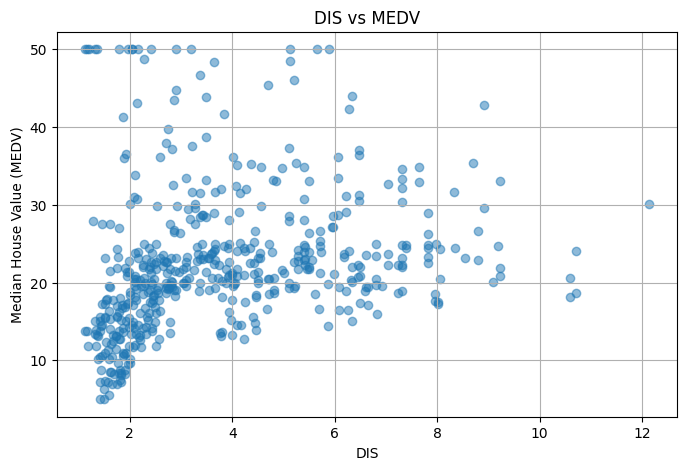

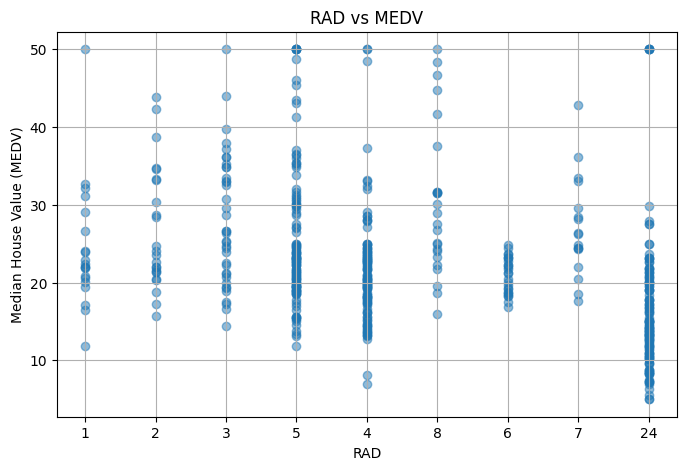

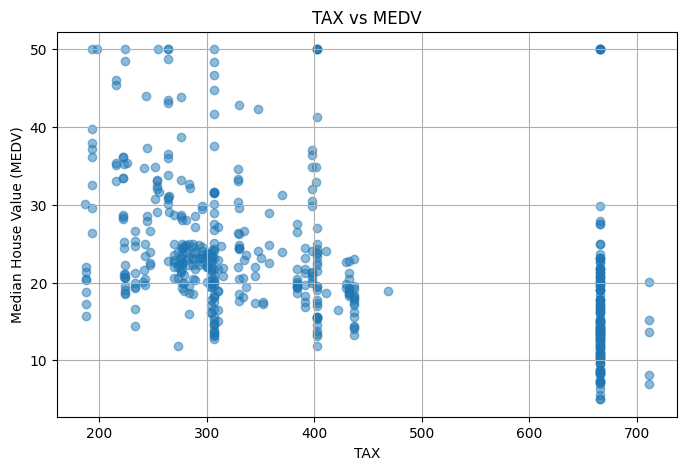

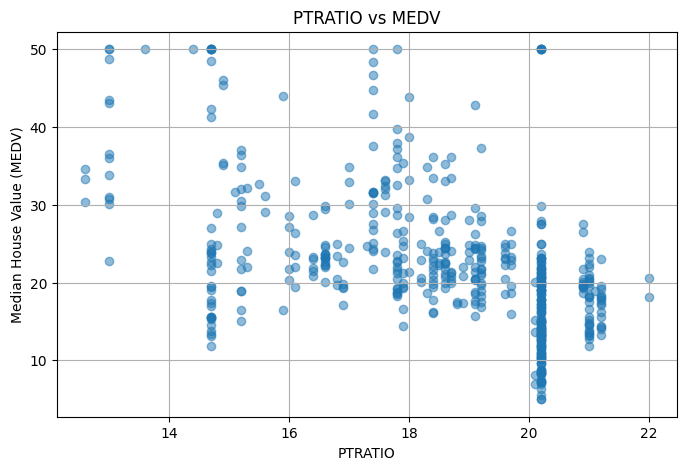

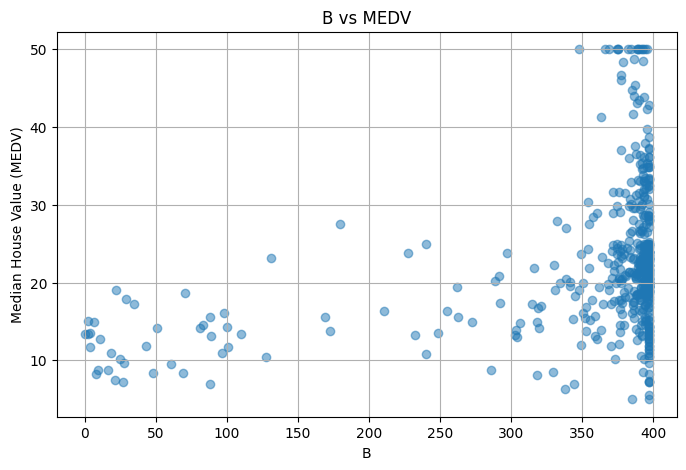

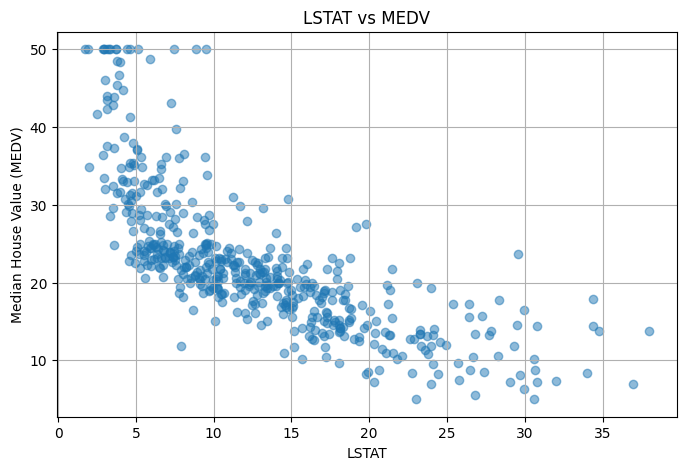

In [ ]:
# 6.0 Create a function to automate scatter plots for all features vs the target variable.
# The function should loop over a list of features and plot scatter plots for each.

def plot_scatter_features(features, target):
    for feature in features:
        plt.figure(figsize=(8, 5))
        plt.scatter(df[feature], target, alpha=0.5)

        plt.title(f'{feature} vs MEDV')
        plt.xlabel(feature)
        plt.ylabel('Median House Value (MEDV)')
        plt.grid(True)
        plt.show()


# Call the function for all independent features
plot_scatter_features(X.columns, y)

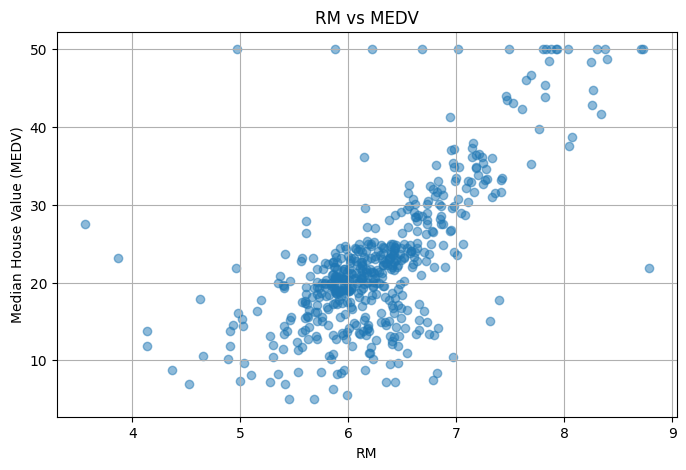

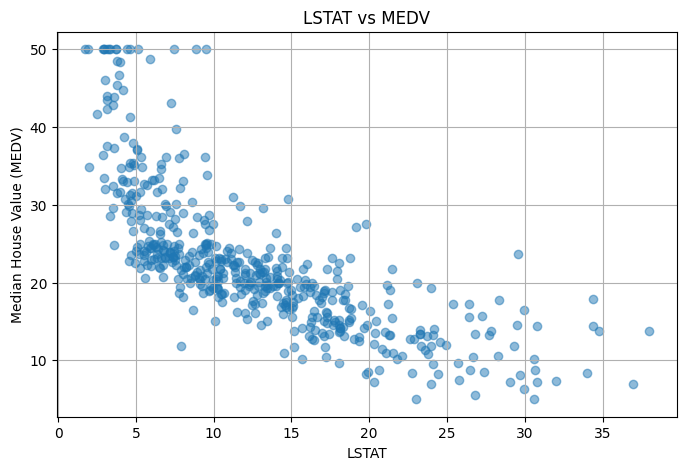

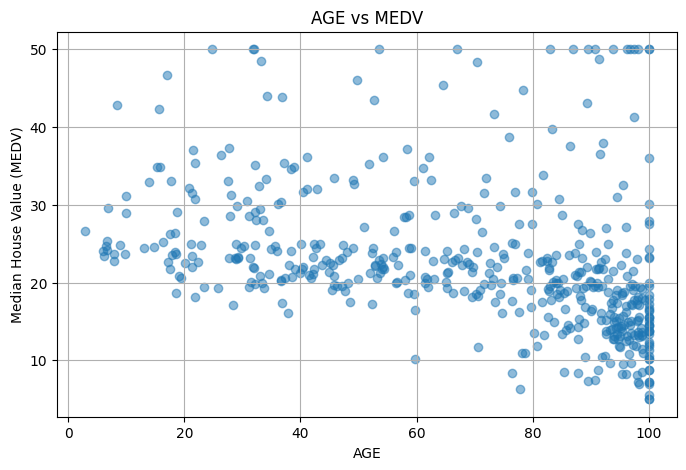

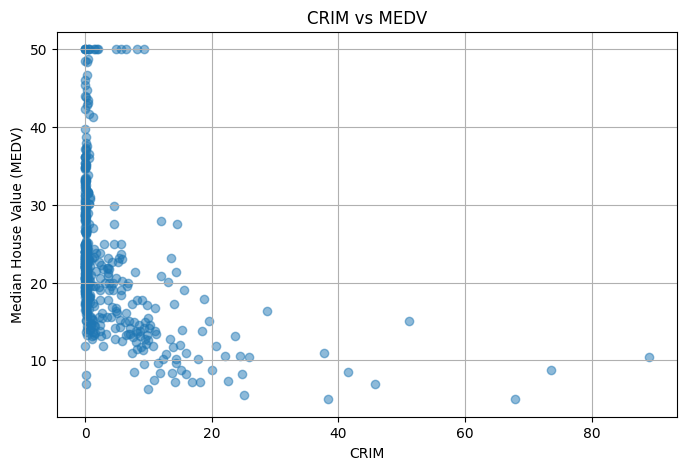

In [ ]:
# 7 Use the function to visualize the relationships between multiple features and the target variable.
# Example: ['RM', 'LSTAT', 'AGE', 'CRIM']
# Target: 'MEDV'

# Select multiple features
selected_features = ['RM', 'LSTAT', 'AGE', 'CRIM']

# Visualize each feature against the target variable MEDV
plot_scatter_features(selected_features, df['MEDV'])

In [ ]:
# 8 ML Model Training ---
# Split the dataset into training and testing sets.
# Use `train_test_split()` from `sklearn.model_selection` with an 80/20 split.

from sklearn.model_selection import train_test_split

# Split the features and target variable
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Display the shapes of the datasets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (404, 13)
Testing features: (102, 13)
Training target: (404,)
Testing target: (102,)


In [ ]:
# Define independent features (X) and target variable (y)
X = df.drop('MEDV', axis=1)
y = df['MEDV']

# Split the dataset into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Display dataset sizes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (404, 13)
X_test shape: (102, 13)
y_train shape: (404,)
y_test shape: (102,)


In [ ]:
# Random Forest Regressor

from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest regression model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model using the training data
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
# Evaluate the model using the test dataset
# Use RMSE (Root Mean Squared Error) and R-squared (R²) to measure how well the Random Forest model predicts house prices.

from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Make predictions using the test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R-squared (R2):", r2)

Mean Squared Error (MSE): 7.901513892156864
Root Mean Squared Error (RMSE): 2.8109631609391226
R-squared (R2): 0.8922527442109116


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

# Define hyperparameters to test
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Initialize GridSearchCV
grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

# Train and tune the model
grid_search.fit(X_train, y_train)

# Display the best parameters
print("Best Parameters:", grid_search.best_params_)

# Select the best model
best_model = grid_search.best_estimator_

print("Hyperparameter tuning completed successfully!")

Best Parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Hyperparameter tuning completed successfully!


In [ ]:
# Make predictions using the tuned model
y_pred_tuned = best_model.predict(X_test)

# Calculate evaluation metrics
mse_tuned = mean_squared_error(y_test, y_pred_tuned)
rmse_tuned = np.sqrt(mse_tuned)
r2_tuned = r2_score(y_test, y_pred_tuned)

# Display results
print("Tuned Model RMSE:", rmse_tuned)
print("Tuned Model R-squared:", r2_tuned)

Tuned Model RMSE: 3.0178478844115904
Tuned Model R-squared: 0.8758088637874195


In [ ]:
# Predict on the test set and calculate the evaluation metrics:
# Predict house prices on the test set
y_pred = best_model.predict(X_test)

# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R-squared (R2):", r2)

Mean Squared Error (MSE): 9.107405853447512
Root Mean Squared Error (RMSE): 3.0178478844115904
R-squared (R2): 0.8758088637874195


In [ ]:
# Predict house prices using new data
# Create new data with hypothetical feature values
new_data = pd.DataFrame({
    'CRIM': [0.2],
    'ZN': [12.5],
    'INDUS': [7.07],
    'CHAS': [0],
    'NOX': [0.5],
    'RM': [6.5],
    'AGE': [68],
    'DIS': [4.0],
    'RAD': [2],
    'TAX': [250],
    'PTRATIO': [17],
    'B': [400],
    'LSTAT': [12]
})

# Predict the house price
predicted_price = best_model.predict(new_data)

# Display the prediction
print("Predicted House Price:", predicted_price[0])

Predicted House Price: 22.32783761231566
